<a href="https://colab.research.google.com/github/MohitSawarkar/GenAi-/blob/main/Gen_AI_practical_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Self Attention Implementation "Man eat Cheese"

In [ ]:
# Self-Attention Implementation for "Man eat cheese"

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Define the input tokens and basic dimensions
tokens = ["Man", "eat", "cheese"]
seq_len = len(tokens)

# Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8
# 2. Initialize toy embeddings for our tokens
# In a real model, these would come from an embedding layer or previous encoder layer
embeddings = torch.randn(seq_len, d_model)

print("Input Embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb.tolist()} (Dimension: {d_model})")

Input Embeddings (Hidden States):
Man: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232, 0.6784184575080872, -1.2345448732376099, -0.04306747764348984, -1.6046669483184814, -0.7521352767944336, 1.6487230062484741, -0.3924786448478699, -1.4036071300506592, -0.7278813123703003, -0.5594301819801331, -0.7688388824462891, 0.7624453902244568] (Dimension: 16)
eat: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667, -0.7581311464309692, 1.078317642211914, 0.8008005619049072, 1.680620551109314, 1.27912437915802, 1.2964228391647339, 0.610466480255127, 1.334737777709961, -0.2316243201494217, 0.041759490966796875, -0.2515752911567688, 0.859858512878418] (Dimension: 16)
cheese: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125, 0.3188803195953369, -0.42451897263526917, 0.3057209253311157, -0.7745925188064575, -1.5575724840164185, 0.9956361055374146, -0.8797858357429504, -0.6011420488357544, -1.274151206016

# Projection (Query, Key, Value)

In [ ]:
# Now, we define the weight matrices for projecting our input embeddings into Queries (Q), Keys (K), and Values (V).

# 3. Define projection weights
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)

# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])


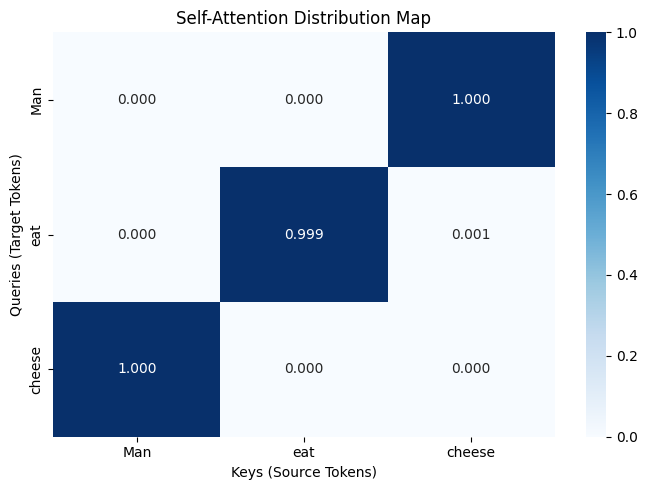

In [ ]:
# Calculate the self-attention distribution map
scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)
attn_distribution = F.softmax(scores, dim=-1)

plt.figure(figsize=(7, 5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True, fmt=".3f", xticklabels=tokens, yticklabels=tokens,
    cmap="Blues", cbar=True, vmin=0, vmax=1
)
plt.title("Self-Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.tight_layout()
plt.show()

In [ ]:
print("\n" + "=" * 60)
print("STEP-BY-STEP ATTENTION CALCULATIONS")
print("=" * 60)

for i, q_token in enumerate(tokens):
    print(f"\n--- Calculations for Query Token: '{q_token}' ---")
    q_vec = Q[i]
    raw_scores, scaled_scores = [], []

    for j, k_token in enumerate(tokens):
        k_vec = K[j]
        dot_prod = torch.dot(q_vec, k_vec).item()
        scaled_prod = dot_prod / (d_k ** 0.5)
        raw_scores.append(dot_prod)
        scaled_scores.append(scaled_prod)
        print(f"Key '{k_token}': Raw Dot Product = {dot_prod:.4f}, Scaled Score = {scaled_prod:.4f}")

    scaled_scores = np.array(scaled_scores)
    exp_scores = np.exp(scaled_scores - np.max(scaled_scores))
    probabilities = exp_scores / np.sum(exp_scores)

    print("\nAttention Probabilities:")
    for token, probability in zip(tokens, probabilities):
        print(f"Key '{token}': {probability:.6f}")

    probability_tensor = torch.tensor(probabilities, dtype=V.dtype)
    context_vector = torch.matmul(probability_tensor, V)
    print("\nContext Vector:\n", context_vector.detach().tolist())


STEP-BY-STEP ATTENTION CALCULATIONS

--- Calculations for Query Token: 'Man' ---
Key 'Man': Raw Dot Product = -10.7053, Scaled Score = -3.7849
Key 'eat': Raw Dot Product = -11.6061, Scaled Score = -4.1034
Key 'cheese': Raw Dot Product = 62.8936, Scaled Score = 22.2362

Attention Probabilities:
Key 'Man': 0.000000
Key 'eat': 0.000000
Key 'cheese': 1.000000

Context Vector:
 [-0.28153765201568604, 2.5002551078796387, -4.627270221710205, -0.3331648111343384, -2.7299487590789795, 0.5726194381713867, 1.9096590280532837, 3.625087022781372]

--- Calculations for Query Token: 'eat' ---
Key 'Man': Raw Dot Product = -84.6923, Scaled Score = -29.9433
Key 'eat': Raw Dot Product = 26.9950, Scaled Score = 9.5442
Key 'cheese': Raw Dot Product = 6.6229, Scaled Score = 2.3416

Attention Probabilities:
Key 'Man': 0.000000
Key 'eat': 0.999256
Key 'cheese': 0.000744

Context Vector:
 [1.2041994333267212, -0.20262236893177032, 0.6607497334480286, 2.9681124687194824, 0.8510885238647461, 0.4842008650302887,

In [ ]:
num_heads = 2
d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

W_q_mha = torch.randn(d_model, d_model)
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)

Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)


Q_split = Q_mha.reshape(seq_len, num_heads, d_k_head).transpose(0, 1)
K_split = K_mha.reshape(seq_len, num_heads, d_k_head).transpose(0, 1)
V_split = V_mha.reshape(seq_len, num_heads, d_v_head).transpose(0, 1)

scores = torch.matmul(Q_split, K_split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_split)

concat_output = head_outputs.transpose(0, 1).contiguous().reshape(seq_len, d_model)
final_output = torch.matmul(concat_output, W_o)

print("Final Multi-Head Attention Output Shape:", final_output.shape)
for token, val in zip(tokens, final_output):
    print(f"\n{token} final attention vector:\n", val.detach().tolist())

Final Multi-Head Attention Output Shape: torch.Size([3, 16])

Man final attention vector:
 [-26.274137496948242, 15.699426651000977, -0.22362184524536133, -0.24244022369384766, 22.99324607849121, -0.22510766983032227, 8.58193302154541, -7.539484024047852, 24.474943161010742, -3.109156608581543, 24.287206649780273, -6.135099411010742, -10.581945419311523, -5.145535945892334, 20.26026725769043, -11.428560256958008]

eat final attention vector:
 [-3.66186785697937, 1.376133680343628, -3.899158000946045, 8.149821281433105, 0.3964192271232605, 2.6331615447998047, -14.900367736816406, -6.042943000793457, 17.70359230041504, -1.500133991241455, 12.177976608276367, 13.210634231567383, 10.124855995178223, -0.0259246826171875, 12.962163925170898, -7.724217414855957]

cheese final attention vector:
 [-24.180145263671875, 28.785184860229492, 8.895611763000488, 2.3695297241210938, 6.505190849304199, -11.329137802124023, 23.453765869140625, 9.0756254196167, 2.675567388534546, -4.521124839782715, 3.49

# Multi-Head Attention Visualization

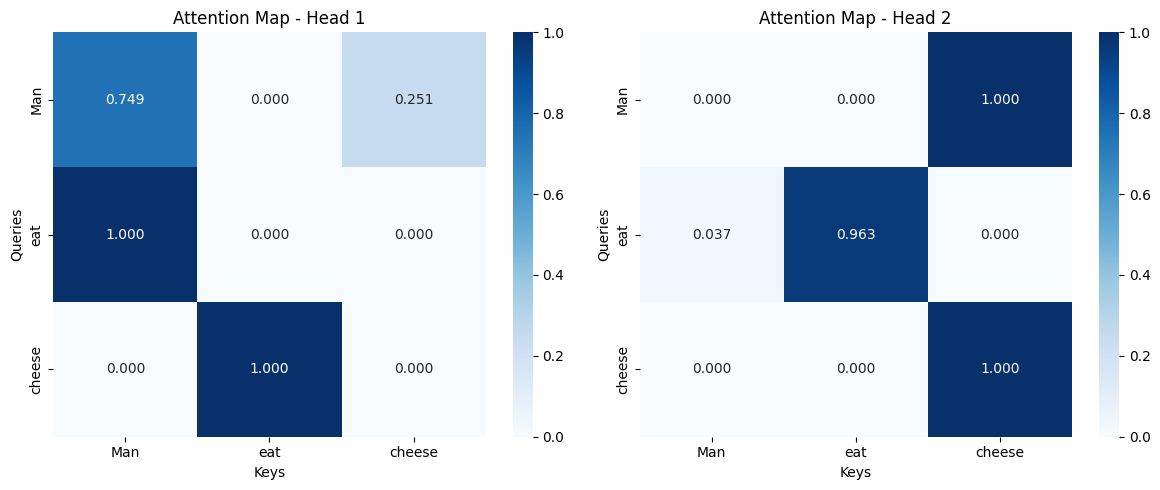


IMPLEMENTATION COMPLETED SUCCESSFULLY
Input Tokens: ['Man', 'eat', 'cheese']
Embedding Shape: torch.Size([3, 16])
Query Shape: torch.Size([3, 8])
Self-Attention Output Shape: torch.Size([3, 8])
Number of Attention Heads: 2
Final Output Shape: torch.Size([3, 16])


In [ ]:
# Calculate single-head attention output to satisfy the summary printing
attention_output = torch.matmul(attn_distribution, V)

fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))

for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(), annot=True, fmt=".3f",
        xticklabels=tokens, yticklabels=tokens, cmap="Blues",
        cbar=True, vmin=0, vmax=1, ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h + 1}")
    axes[h].set_xlabel("Keys")
    axes[h].set_ylabel("Queries")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("IMPLEMENTATION COMPLETED SUCCESSFULLY")
print("=" * 60)

print("Input Tokens:", tokens)
print("Embedding Shape:", embeddings.shape)
print("Query Shape:", Q.shape)
print("Self-Attention Output Shape:", attention_output.shape)
print("Number of Attention Heads:", num_heads)
print("Final Output Shape:", final_output.shape)

# Self Attention Implementation "Cat sat on the mat"

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Define the input tokens and basic dimensions
tokens_cat = ["Cat", "sat", "on", "the", "mat"]
seq_len_cat = len(tokens_cat)

# Let's keep the same embedding and projection dimensions
d_model = 16
d_k = 8
d_v = 8

# 2. Initialize toy embeddings for our tokens
embeddings_cat = torch.randn(seq_len_cat, d_model)

print("Input Embeddings for 'Cat sat on the mat':")
for token, emb in zip(tokens_cat, embeddings_cat):
    print(f"{token}: {emb.tolist()} (Dimension: {d_model})")

Input Embeddings for 'Cat sat on the mat':
Cat: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232, 0.6784184575080872, -1.2345448732376099, -0.04306747764348984, -1.6046669483184814, -0.7521352767944336, 1.6487230062484741, -0.3924786448478699, -1.4036071300506592, -0.7278813123703003, -0.5594301819801331, -0.7688388824462891, 0.7624453902244568] (Dimension: 16)
sat: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667, -0.7581311464309692, 1.078317642211914, 0.8008005619049072, 1.680620551109314, 1.27912437915802, 1.2964228391647339, 0.610466480255127, 1.334737777709961, -0.2316243201494217, 0.041759490966796875, -0.2515752911567688, 0.859858512878418] (Dimension: 16)
on: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125, 0.3188803195953369, -0.42451897263526917, 0.3057209253311157, -0.7745925188064575, -1.5575724840164185, 0.9956361055374146, -0.8797858357429504, -0.6011420488357544, -1.2741512

In [ ]:
# 3. Define projection weights
W_q_cat = torch.randn(d_model, d_k)
W_k_cat = torch.randn(d_model, d_k)
W_v_cat = torch.randn(d_model, d_v)

# Compute Q, K, V
Q_cat = torch.matmul(embeddings_cat, W_q_cat)
K_cat = torch.matmul(embeddings_cat, W_k_cat)
V_cat = torch.matmul(embeddings_cat, W_v_cat)

print("Queries (Q) Shape:", Q_cat.shape)
print("Keys (K) Shape:", K_cat.shape)
print("Values (V) Shape:", V_cat.shape)

Queries (Q) Shape: torch.Size([5, 8])
Keys (K) Shape: torch.Size([5, 8])
Values (V) Shape: torch.Size([5, 8])


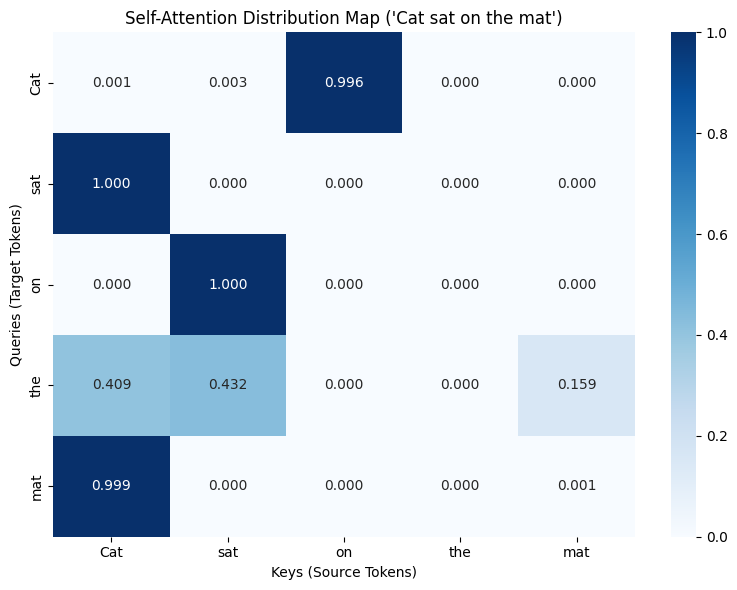

In [ ]:
# Calculate the self-attention distribution map
scores_cat = torch.matmul(Q_cat, K_cat.transpose(-2, -1)) / (d_k ** 0.5)
attn_distribution_cat = F.softmax(scores_cat, dim=-1)

plt.figure(figsize=(8, 6))
sns.heatmap(
    attn_distribution_cat.detach().numpy(),
    annot=True, fmt=".3f", xticklabels=tokens_cat, yticklabels=tokens_cat,
    cmap="Blues", cbar=True, vmin=0, vmax=1
)
plt.title("Self-Attention Distribution Map ('Cat sat on the mat')")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.tight_layout()
plt.show()

In [ ]:
print("\n" + "=" * 60)
print("STEP-BY-STEP ATTENTION CALCULATIONS FOR 'CAT SAT ON THE MAT'")
print("=" * 60)

for i, q_token in enumerate(tokens_cat):
    print(f"\n--- Calculations for Query Token: '{q_token}' ---")
    q_vec = Q_cat[i]
    raw_scores, scaled_scores = [], []

    for j, k_token in enumerate(tokens_cat):
        k_vec = K_cat[j]
        dot_prod = torch.dot(q_vec, k_vec).item()
        scaled_prod = dot_prod / (d_k ** 0.5)
        raw_scores.append(dot_prod)
        scaled_scores.append(scaled_prod)
        print(f"Key '{k_token}': Raw Dot Product = {dot_prod:.4f}, Scaled Score = {scaled_prod:.4f}")

    scaled_scores = np.array(scaled_scores)
    exp_scores = np.exp(scaled_scores - np.max(scaled_scores))
    probabilities = exp_scores / np.sum(exp_scores)

    print("\nAttention Probabilities:")
    for token, probability in zip(tokens_cat, probabilities):
        print(f"Key '{token}': {probability:.6f}")

    probability_tensor = torch.tensor(probabilities, dtype=V_cat.dtype)
    context_vector = torch.matmul(probability_tensor, V_cat)
    print("\nContext Vector:\n", context_vector.detach().tolist())


STEP-BY-STEP ATTENTION CALCULATIONS FOR 'CAT SAT ON THE MAT'

--- Calculations for Query Token: 'Cat' ---
Key 'Cat': Raw Dot Product = 5.9778, Scaled Score = 2.1135
Key 'sat': Raw Dot Product = 11.1912, Scaled Score = 3.9567
Key 'on': Raw Dot Product = 27.3907, Scaled Score = 9.6841
Key 'the': Raw Dot Product = -4.3818, Scaled Score = -1.5492
Key 'mat': Raw Dot Product = -30.0078, Scaled Score = -10.6093

Attention Probabilities:
Key 'Cat': 0.000513
Key 'sat': 0.003243
Key 'on': 0.996230
Key 'the': 0.000013
Key 'mat': 0.000000

Context Vector:
 [6.250803470611572, 0.49294739961624146, 4.986205577850342, -4.340506076812744, -7.153112411499023, 5.436171531677246, 3.268028736114502, 0.12373974919319153]

--- Calculations for Query Token: 'sat' ---
Key 'Cat': Raw Dot Product = 100.5504, Scaled Score = 35.5499
Key 'sat': Raw Dot Product = -1.5357, Scaled Score = -0.5429
Key 'on': Raw Dot Product = 11.7559, Scaled Score = 4.1564
Key 'the': Raw Dot Product = -21.9925, Scaled Score = -7.7755


In [ ]:
# Multi-Head Attention Configuration
num_heads = 2
d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

W_q_mha_cat = torch.randn(d_model, d_model)
W_k_mha_cat = torch.randn(d_model, d_model)
W_v_mha_cat = torch.randn(d_model, d_model)
W_o_cat = torch.randn(d_model, d_model)

Q_mha_cat = torch.matmul(embeddings_cat, W_q_mha_cat)
K_mha_cat = torch.matmul(embeddings_cat, W_k_mha_cat)
V_mha_cat = torch.matmul(embeddings_cat, W_v_mha_cat)

Q_split_cat = Q_mha_cat.reshape(seq_len_cat, num_heads, d_k_head).transpose(0, 1)
K_split_cat = K_mha_cat.reshape(seq_len_cat, num_heads, d_k_head).transpose(0, 1)
V_split_cat = V_mha_cat.reshape(seq_len_cat, num_heads, d_v_head).transpose(0, 1)

scores_mha_cat = torch.matmul(Q_split_cat, K_split_cat.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions_cat = F.softmax(scores_mha_cat, dim=-1)
head_outputs_cat = torch.matmul(distributions_cat, V_split_cat)

concat_output_cat = head_outputs_cat.transpose(0, 1).contiguous().reshape(seq_len_cat, d_model)
final_output_cat = torch.matmul(concat_output_cat, W_o_cat)

print("Final Multi-Head Attention Output Shape:", final_output_cat.shape)
for token, val in zip(tokens_cat, final_output_cat):
    print(f"\n{token} final attention vector:\n", val.detach().tolist())

Final Multi-Head Attention Output Shape: torch.Size([5, 16])

Cat final attention vector:
 [2.4339044094085693, -17.530582427978516, -25.42690086364746, 4.031478404998779, 3.4665064811706543, -0.4888699948787689, 4.350336074829102, 18.42599868774414, 1.1476291418075562, -13.964353561401367, 5.195918560028076, -6.320756435394287, -4.910580635070801, 10.238478660583496, -6.323831081390381, -2.85797119140625]

sat final attention vector:
 [-17.60268211364746, 12.97557544708252, 15.61893367767334, 18.887645721435547, 20.405773162841797, -2.437636613845825, -4.468374252319336, -44.7711181640625, 17.645965576171875, 9.322894096374512, 8.058148384094238, 10.258156776428223, 2.3042197227478027, -13.520427703857422, 7.556919097900391, -30.70536231994629]

on final attention vector:
 [5.351263046264648, 6.63056755065918, 2.2014353275299072, -2.5854969024658203, 7.207454204559326, -14.352373123168945, 4.3413286209106445, 23.405284881591797, 12.014799118041992, 1.0460880994796753, 21.5938434600830

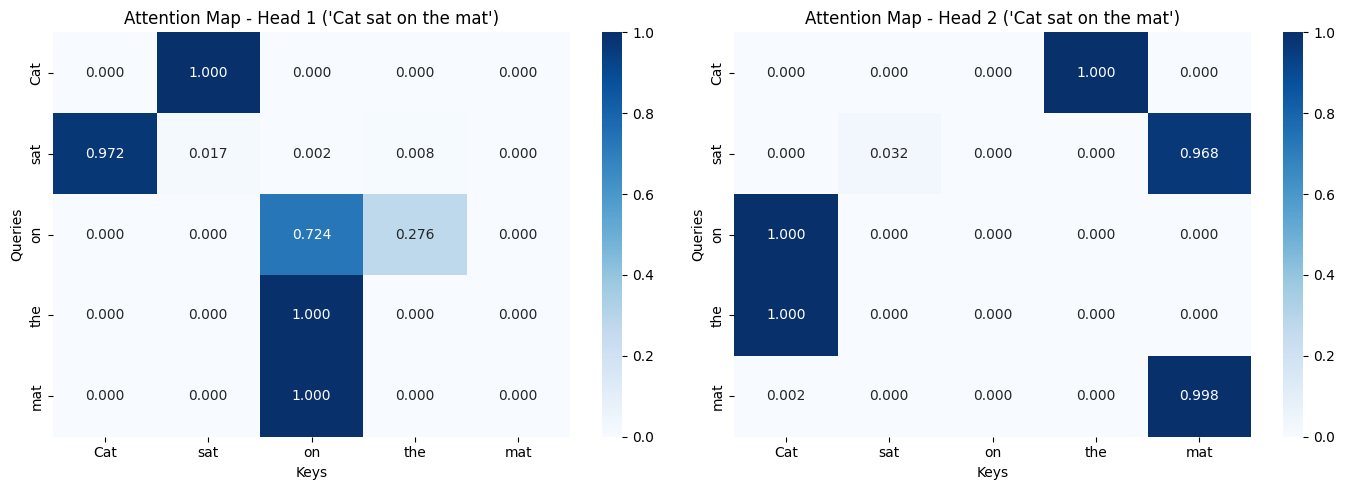


IMPLEMENTATION COMPLETED SUCCESSFULLY FOR 'CAT SAT ON THE MAT'
Input Tokens: ['Cat', 'sat', 'on', 'the', 'mat']
Embedding Shape: torch.Size([5, 16])
Query Shape: torch.Size([5, 8])
Self-Attention Output Shape: torch.Size([5, 8])
Number of Attention Heads: 2
Final Output Shape: torch.Size([5, 16])


In [ ]:
# Multi-Head Attention Visualization
fig, axes = plt.subplots(1, num_heads, figsize=(14, 5))

for h in range(num_heads):
    sns.heatmap(
        distributions_cat[h].detach().numpy(), annot=True, fmt=".3f",
        xticklabels=tokens_cat, yticklabels=tokens_cat, cmap="Blues",
        cbar=True, vmin=0, vmax=1, ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h + 1} ('Cat sat on the mat')")
    axes[h].set_xlabel("Keys")
    axes[h].set_ylabel("Queries")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("IMPLEMENTATION COMPLETED SUCCESSFULLY FOR 'CAT SAT ON THE MAT'")
print("=" * 60)

attention_output_cat = torch.matmul(attn_distribution_cat, V_cat)
print("Input Tokens:", tokens_cat)
print("Embedding Shape:", embeddings_cat.shape)
print("Query Shape:", Q_cat.shape)
print("Self-Attention Output Shape:", attention_output_cat.shape)
print("Number of Attention Heads:", num_heads)
print("Final Output Shape:", final_output_cat.shape)